# Hydrodynamic model of the Southern North Sea

Load the data using [MIKE IO](https://dhi.github.io/mikeio) and review it. Data is stored as a dfsu file. Specific points are stored in a dfs0 file. 

In [8]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from datasets.code.helper import get_altimetry_obs, get_wl_point_obs, get_u_v_point_obs

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

In [9]:
# mr_fldr = "../output_sample/"
mr_fldr = "datasets/output_sample/"

fldr = "datasets/observations/" 
msh = mikeio.open("datasets/input/Mesh_8000_elems_HD_v2.mesh")

## Load data

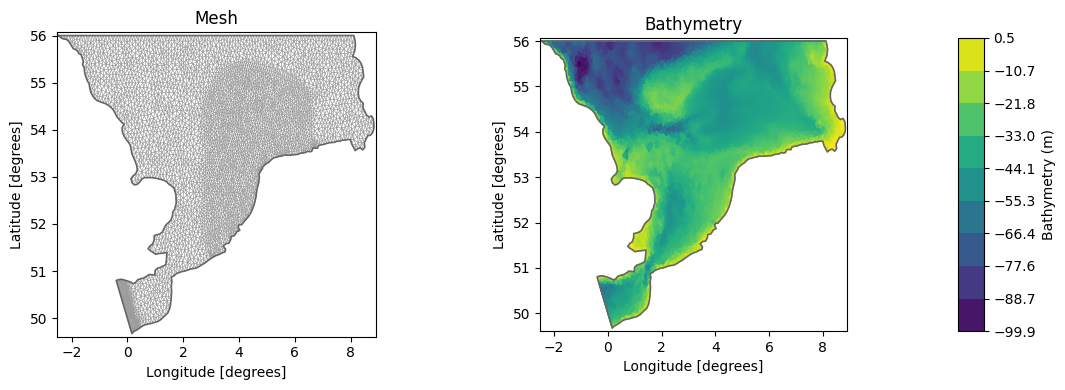

In [10]:
# Load data

dfs = mikeio.open(f"{mr_fldr}Area.dfsu")

geom = dfs.geometry

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()


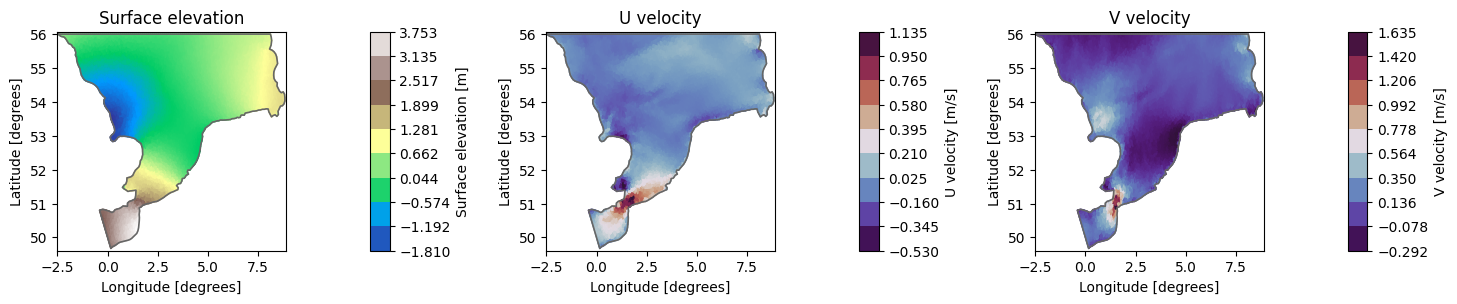

In [11]:
# Extract time series 

ds = dfs.read(time = slice("2022-01-03", "2023-12-31"))

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1], title="U velocity", cmap = "twilight_shifted")
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()

## SHRED from random simulated fixed sensors

In [12]:
# Remove locations with NaNs (same NaNs locations for surface elevation and velocities)

H = ds["Surface elevation"].values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
U = ds["U velocity"].values[:,~np.isnan(ds["U velocity"].values).any(axis=0)]
V = ds["V velocity"].values[:,~np.isnan(ds["V velocity"].values).any(axis=0)]

In [16]:
# Data manager

from pyshred.processor.data_manager import DataManager

manager = DataManager(
    lags = 48, # 1 day of past measurements for predictions 
    train_size = 0.8,
    val_size = 0.1,
    test_size = 0.1
)

manager.add_data(
    data = H,
    id = "Surface elevation",
    random = 3, # 3 sensors monitoring surface elevation at random locations
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = U,
    id = "U velocity",
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = V,
    id = "V velocity",
    compress = 100 # 100 POD modes for compressive training 
)

train_dataset, val_dataset, test_dataset= manager.prepare()


In [17]:
manager.sensor_summary_df

,data id,sensor_number,type,loc/traj
0,Surface elevation,0,stationary (random),"(5509,)"
1,Surface elevation,1,stationary (random),"(6675,)"
2,Surface elevation,2,stationary (random),"(5719,)"


In [18]:
manager.sensor_measurements_df

,Surface elevation-0,Surface elevation-1,Surface elevation-2
0,0.722897,0.961812,0.611811
1,0.713896,0.915310,0.334527
2,0.700216,0.871828,0.112656
3,0.663814,0.817698,-0.068251
4,0.592297,0.732786,-0.243218
...,...,...,...
332,-0.008448,-0.072152,-0.979157
333,-0.105286,-0.183587,-0.876307
334,-0.192345,-0.270882,-0.687941
335,-0.264168,-0.333951,-0.424219


In [20]:
# SHRED fitting


from pyshred.models.shred import SHRED
shred = SHRED(sequence_model = "LSTM", decoder_model = "MLP", latent_forecaster = None)

val_errors = shred.fit(train_dataset = train_dataset, val_dataset = val_dataset, num_epochs = 100, verbose = True)

Fitting SHRED...
Epoch 1: Average training loss = 0.224291
Validation MSE (epoch 1): 0.310778
Epoch 2: Average training loss = 0.116583
Validation MSE (epoch 2): 0.186122
Epoch 3: Average training loss = 0.058138
Validation MSE (epoch 3): 0.183173
Epoch 4: Average training loss = 0.037999
Validation MSE (epoch 4): 0.174219
Epoch 5: Average training loss = 0.041238
Validation MSE (epoch 5): 0.172283
Epoch 6: Average training loss = 0.037771
Validation MSE (epoch 6): 0.170073
Epoch 7: Average training loss = 0.037062
Validation MSE (epoch 7): 0.169996
Epoch 8: Average training loss = 0.035221
Validation MSE (epoch 8): 0.170940
Epoch 9: Average training loss = 0.035514
Validation MSE (epoch 9): 0.171624
Epoch 10: Average training loss = 0.035041
Validation MSE (epoch 10): 0.171316
Epoch 11: Average training loss = 0.035125
Validation MSE (epoch 11): 0.170781
Epoch 12: Average training loss = 0.034717
Validation MSE (epoch 12): 0.170345
Epoch 13: Average training loss = 0.034702
Validation

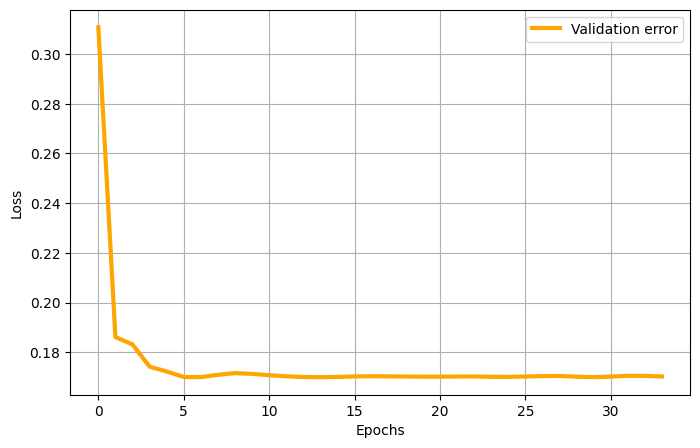

In [21]:
# Validation loss during training

plt.figure(figsize = (8,5))
plt.plot(val_errors, 'orange', linewidth = 3, label = 'Validation error')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

In [22]:
# Mean squared errors

train_mse = shred.evaluate(dataset = train_dataset)
val_mse = shred.evaluate(dataset = val_dataset)
test_mse = shred.evaluate(dataset = test_dataset)
print(f"Train MSE: {train_mse:.3f}")
print(f"Val   MSE: {val_mse:.3f}")
print(f"Test  MSE: {test_mse:.3f}")

Train MSE: 0.033
Val   MSE: 0.170
Test  MSE: 0.298


In [32]:
# Reconstruction from test sensors

from pyshred.engine.engine import SHREDEngine

engine = SHREDEngine(manager, shred)
test_reconstruction = engine.sensor_to_latent(manager.test_sensor_measurements)
test_reconstruction = engine.decode(test_reconstruction)

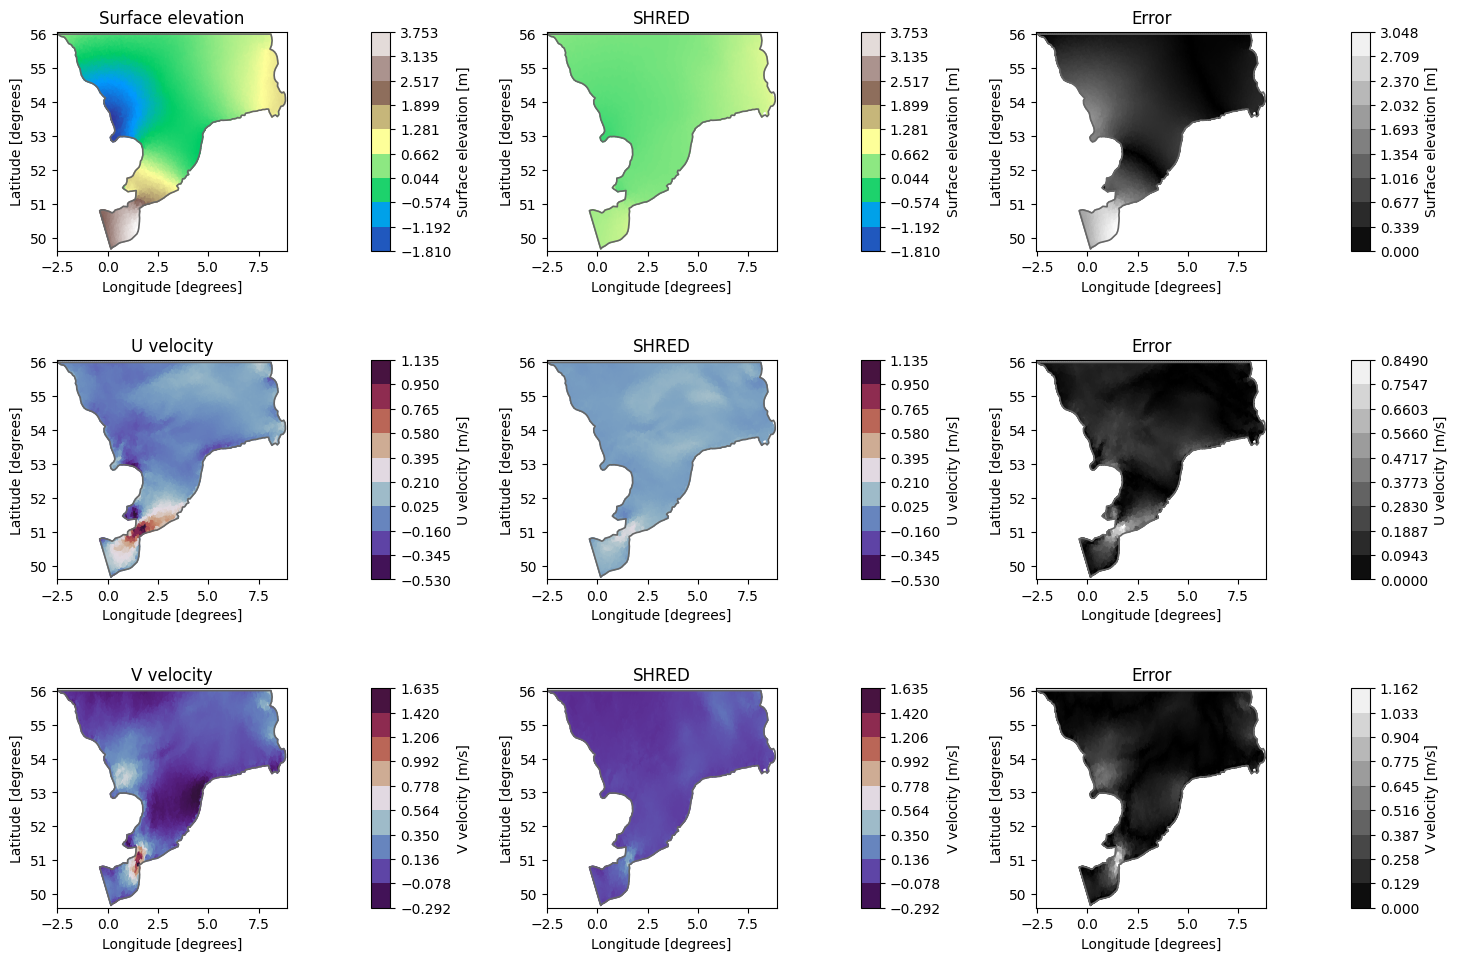

In [33]:
# Build datasets with SHRED reconstructions and errors (filling NaN locations for plotting)

times_test = ds.time[-test_reconstruction["Surface elevation"].shape[0]:]

H_reconstruction = np.full((test_reconstruction["Surface elevation"].shape[0], ds["Surface elevation"].values.shape[1]), np.nan)
H_reconstruction[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)] = test_reconstruction["Surface elevation"]

U_reconstruction = np.full((test_reconstruction["U velocity"].shape[0], ds["U velocity"].values.shape[1]), np.nan)
U_reconstruction[:,~np.isnan(ds["U velocity"].values).any(axis=0)] = test_reconstruction["U velocity"]

V_reconstruction = np.full((test_reconstruction["V velocity"].shape[0], ds["V velocity"].values.shape[1]), np.nan)
V_reconstruction[:,~np.isnan(ds["V velocity"].values).any(axis=0)] = test_reconstruction["V velocity"]

ds_shred = mikeio.Dataset([
    mikeio.DataArray(data=H_reconstruction, time=times_test, item=ds.items[0], geometry=geom),
    mikeio.DataArray(data=U_reconstruction, time=times_test, item=ds.items[1], geometry=geom),
    mikeio.DataArray(data=V_reconstruction, time=times_test, item=ds.items[2], geometry=geom),
])

ds_error = mikeio.Dataset([
    mikeio.DataArray(data=np.sqrt((ds["Surface elevation"].sel(time=times_test).values - ds_shred["Surface elevation"].values)**2), time=times_test, item=ds.items[0], geometry=geom),
    mikeio.DataArray(data=np.sqrt((ds["U velocity"].sel(time=times_test).values - ds_shred["U velocity"].values)**2),          time=times_test, item=ds.items[1], geometry=geom),
    mikeio.DataArray(data=np.sqrt((ds["V velocity"].sel(time=times_test).values - ds_shred["V velocity"].values)**2),          time=times_test, item=ds.items[2], geometry=geom),
])

# Qualitative comparison

plot_time = ds_shred.time[-1]
fig,axs = plt.subplots(3, 3, figsize=(15,10))
vmin = min(np.nanmin(ds["Surface elevation"].sel(time=plot_time).values), np.nanmin(ds_shred["Surface elevation"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["Surface elevation"].sel(time=plot_time).values), np.nanmax(ds_shred["Surface elevation"].sel(time=plot_time).values))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,0], title="Surface elevation", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_shred["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,1], title="SHRED", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_error["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["U velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["U velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["U velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["U velocity"].sel(time=plot_time).values))
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1,0], title="U velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["U velocity"].sel(time=plot_time).plot(ax=axs[1,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["U velocity"].sel(time=plot_time).plot(ax=axs[1,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["V velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["V velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["V velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["V velocity"].sel(time=plot_time).values))
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2,0], title="V velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["V velocity"].sel(time=plot_time).plot(ax=axs[2,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["V velocity"].sel(time=plot_time).plot(ax=axs[2,2], title="Error", cmap = "gray")

plt.tight_layout()
plt.show()


## SHRED from in-situ water level data (fixed sensors)


<Axes: >

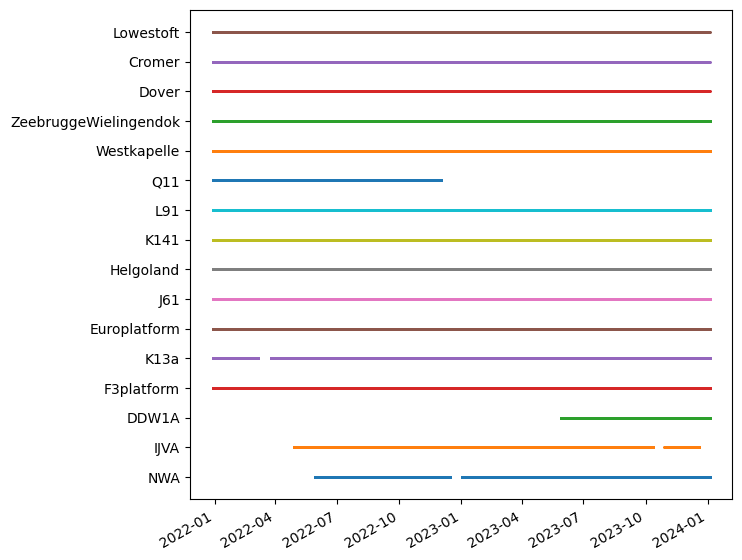

In [34]:
# Temporal coverage of in-situ stations

wllist = get_wl_point_obs()

ms.plotting.temporal_coverage(wllist)

Text(0.5, 1.0, 'Water level stations')

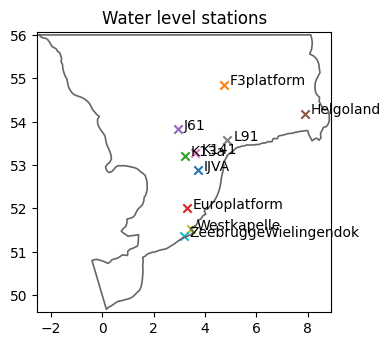

In [35]:
# Select stations with full temporal coverage

stations = []
for i in range(len(wllist)):
    if ds.time.isin(wllist[i].time).all():
        stations.append(wllist[i])

ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (4,4));
plt.tight_layout()
plt.title("Water level stations")

In [36]:
# Extract water level measurements

measurements = np.zeros((ds.time.shape[0], len(stations)))

for i in range(len(stations)):
    
    stn_data = pd.read_csv(fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"][ds.time.strftime("%Y-%m-%d %H:%M:%S")].values

In [37]:
# Remove locations with NaNs (same NaNs locations for surface elevation and velocities)

H = ds["Surface elevation"].values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
U = ds["U velocity"].values[:,~np.isnan(ds["U velocity"].values).any(axis=0)]
V = ds["V velocity"].values[:,~np.isnan(ds["V velocity"].values).any(axis=0)]

In [38]:
H.shape,U.shape,V.shape,measurements.shape

((337, 8551), (337, 8551), (337, 8551), (337, 10))

In [39]:
# Data manager

manager = DataManager(
    lags = 48, # 1 day of past measurements for predictions 
    train_size = 0.8,
    val_size = 0.1,
    test_size = 0.1
)

manager.add_data(
    data = H,
    id = "Surface elevation",
    measurements = measurements,
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = U,
    id = "U velocity",
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = V,
    id = "V velocity",
    compress = 100 # 100 POD modes for compressive training 
)

train_dataset, val_dataset, test_dataset= manager.prepare()


In [40]:
manager.sensor_summary_df

,data id,sensor_number,type,loc/traj
0,Surface elevation,0,measurement,None
1,Surface elevation,1,measurement,None
2,Surface elevation,2,measurement,None
3,Surface elevation,3,measurement,None
4,Surface elevation,4,measurement,None
5,Surface elevation,5,measurement,None
6,Surface elevation,6,measurement,None
7,Surface elevation,7,measurement,None
8,Surface elevation,8,measurement,None
9,Surface elevation,9,measurement,None


In [41]:
manager.sensor_measurements_df

,Surface elevation-0,Surface elevation-1,Surface elevation-2,Surface elevation-3,Surface elevation-4,Surface elevation-5,Surface elevation-6,Surface elevation-7,Surface elevation-8,Surface elevation-9
0,0.6303,0.4325,0.6378,0.0619,0.7562,-0.3209,0.7204,0.7459,-0.1294,-0.3642
1,0.6072,0.4225,0.6978,-0.0281,0.8061,-0.2059,0.7604,0.8859,-0.3994,-0.6142
2,0.6735,0.4225,0.8178,-0.1181,0.8161,-0.0259,0.8504,0.9659,-0.5694,-0.8242
3,0.8853,0.4025,0.8478,-0.1581,0.8061,0.1741,0.9304,1.0159,-0.7294,-0.9342
4,0.8426,0.3725,0.8178,-0.1681,0.7562,0.4041,0.9404,1.0659,-0.7794,-0.9342
...,...,...,...,...,...,...,...,...,...,...
332,-0.1710,0.0425,0.0178,-0.4981,-0.0738,0.7141,0.1204,0.3659,-0.8794,-0.6742
333,-0.2903,-0.0075,-0.1022,-0.3881,-0.2538,0.8341,-0.0096,0.2559,-0.5294,-0.1842
334,-0.3590,-0.0975,-0.2822,-0.2281,-0.4238,0.9441,-0.1396,0.1059,-0.0994,0.3458
335,-0.3753,-0.0975,-0.4422,0.0519,-0.5838,0.9741,-0.2996,0.0059,0.4206,0.9658


In [42]:
# SHRED fitting

shred = SHRED(sequence_model = "LSTM", decoder_model = "MLP", latent_forecaster = None)

val_errors = shred.fit(train_dataset = train_dataset, val_dataset = val_dataset, num_epochs = 100, verbose = True)

Fitting SHRED...
Epoch 1: Average training loss = 0.221209
Validation MSE (epoch 1): 0.286159
Epoch 2: Average training loss = 0.099935
Validation MSE (epoch 2): 0.199984
Epoch 3: Average training loss = 0.060226
Validation MSE (epoch 3): 0.171294
Epoch 4: Average training loss = 0.038706
Validation MSE (epoch 4): 0.177582
Epoch 5: Average training loss = 0.042026
Validation MSE (epoch 5): 0.175119
Epoch 6: Average training loss = 0.038064
Validation MSE (epoch 6): 0.177424
Epoch 7: Average training loss = 0.037113
Validation MSE (epoch 7): 0.171283
Epoch 8: Average training loss = 0.035357
Validation MSE (epoch 8): 0.170351
Epoch 9: Average training loss = 0.035684
Validation MSE (epoch 9): 0.169735
Epoch 10: Average training loss = 0.035305
Validation MSE (epoch 10): 0.170196
Epoch 11: Average training loss = 0.034995
Validation MSE (epoch 11): 0.169768
Epoch 12: Average training loss = 0.035009
Validation MSE (epoch 12): 0.170058
Epoch 13: Average training loss = 0.034931
Validation

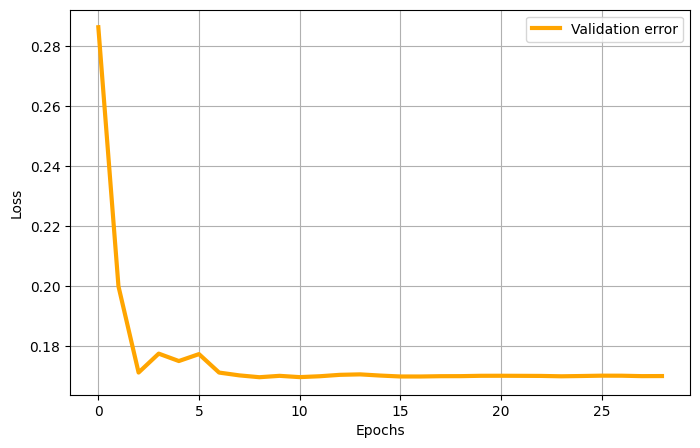

In [43]:
# Validation loss during training

plt.figure(figsize = (8,5))
plt.plot(val_errors, 'orange', linewidth = 3, label = 'Validation error')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

In [44]:
# Mean squared errors

train_mse = shred.evaluate(dataset = train_dataset)
val_mse = shred.evaluate(dataset = val_dataset)
test_mse = shred.evaluate(dataset = test_dataset)
print(f"Train MSE: {train_mse:.3f}")
print(f"Val   MSE: {val_mse:.3f}")
print(f"Test  MSE: {test_mse:.3f}")

Train MSE: 0.034
Val   MSE: 0.170
Test  MSE: 0.298


In [46]:
# Reconstruction from test sensors

from pyshred.engine.engine import SHREDEngine

engine = SHREDEngine(manager, shred)
test_latent_from_sensors = engine.sensor_to_latent(manager.test_sensor_measurements)
test_reconstruction = engine.decode(test_latent_from_sensors)

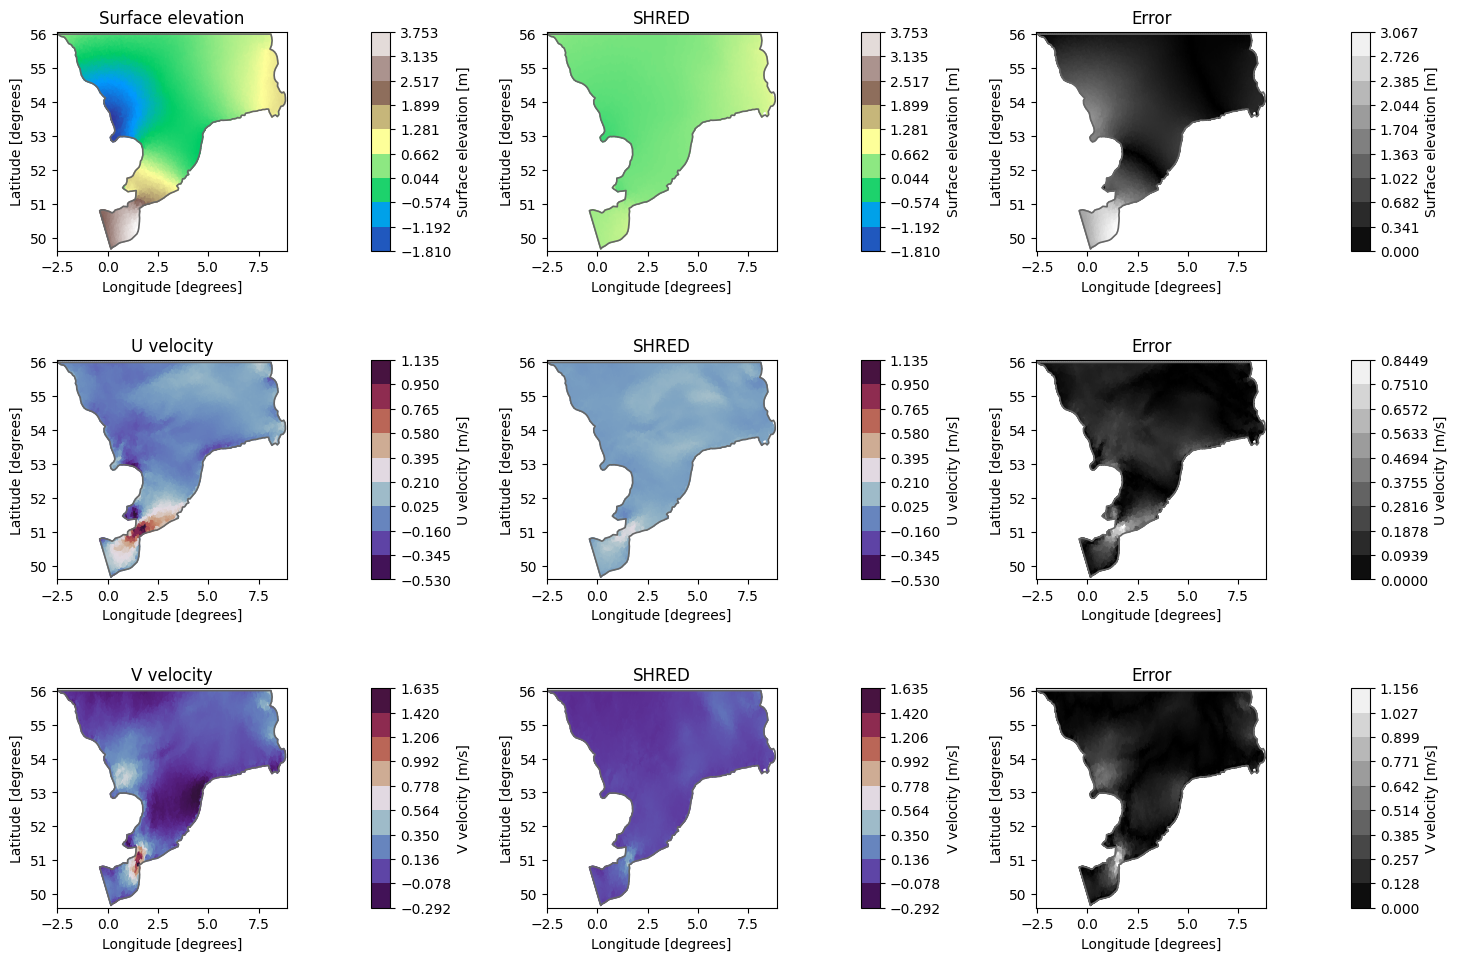

In [48]:
# Build datasets with SHRED reconstructions and errors (filling NaN locations for plotting)

times_test = ds.time[-test_reconstruction["Surface elevation"].shape[0]:]

H_reconstruction = np.full((test_reconstruction["Surface elevation"].shape[0], ds["Surface elevation"].values.shape[1]), np.nan)
H_reconstruction[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)] = test_reconstruction["Surface elevation"]

U_reconstruction = np.full((test_reconstruction["U velocity"].shape[0], ds["U velocity"].values.shape[1]), np.nan)
U_reconstruction[:,~np.isnan(ds["U velocity"].values).any(axis=0)] = test_reconstruction["U velocity"]

V_reconstruction = np.full((test_reconstruction["V velocity"].shape[0], ds["V velocity"].values.shape[1]), np.nan)
V_reconstruction[:,~np.isnan(ds["V velocity"].values).any(axis=0)] = test_reconstruction["V velocity"]

ds_shred = mikeio.Dataset([
    mikeio.DataArray(data=H_reconstruction, time=times_test, item=ds.items[0], geometry=geom),
    mikeio.DataArray(data=U_reconstruction, time=times_test, item=ds.items[1], geometry=geom),
    mikeio.DataArray(data=V_reconstruction, time=times_test, item=ds.items[2], geometry=geom),
])

ds_error = mikeio.Dataset([
    mikeio.DataArray(data=np.sqrt((ds["Surface elevation"].sel(time=times_test).values - ds_shred["Surface elevation"].values)**2), time=times_test, item=ds.items[0], geometry=geom),
    mikeio.DataArray(data=np.sqrt((ds["U velocity"].sel(time=times_test).values - ds_shred["U velocity"].values)**2),          time=times_test, item=ds.items[1], geometry=geom),
    mikeio.DataArray(data=np.sqrt((ds["V velocity"].sel(time=times_test).values - ds_shred["V velocity"].values)**2),          time=times_test, item=ds.items[2], geometry=geom),
])

# Qualitative comparison

plot_time = ds_shred.time[-1]
fig,axs = plt.subplots(3, 3, figsize=(15,10))
vmin = min(np.nanmin(ds["Surface elevation"].sel(time=plot_time).values), np.nanmin(ds_shred["Surface elevation"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["Surface elevation"].sel(time=plot_time).values), np.nanmax(ds_shred["Surface elevation"].sel(time=plot_time).values))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,0], title="Surface elevation", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_shred["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,1], title="SHRED", cmap = "terrain", vmin = vmin, vmax = vmax)
ds_error["Surface elevation"].sel(time=plot_time).plot(ax=axs[0,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["U velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["U velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["U velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["U velocity"].sel(time=plot_time).values))
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1,0], title="U velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["U velocity"].sel(time=plot_time).plot(ax=axs[1,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["U velocity"].sel(time=plot_time).plot(ax=axs[1,2], title="Error", cmap = "gray")

vmin = min(np.nanmin(ds["V velocity"].sel(time=plot_time).values), np.nanmin(ds_shred["V velocity"].sel(time=plot_time).values))
vmax = max(np.nanmax(ds["V velocity"].sel(time=plot_time).values), np.nanmax(ds_shred["V velocity"].sel(time=plot_time).values))
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2,0], title="V velocity", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_shred["V velocity"].sel(time=plot_time).plot(ax=axs[2,1], title="SHRED", cmap = "twilight_shifted", vmin = vmin, vmax = vmax)
ds_error["V velocity"].sel(time=plot_time).plot(ax=axs[2,2], title="Error", cmap = "gray")

plt.tight_layout()
plt.show()
